# Humanoid robotics patents
**Sector:** Humanoid Robots · **Client:** Electrolux · **Group:** 34

How has humanoid patenting changed, who is filing, and whose mature patent portfolio looks strongest?

**Data.** This notebook uses aggregate PATSTAT PROD results from Imma's Steps 0–3. It recalculates the comparisons and firm rankings from the inputs shown in the code. The family-level TIP exports, intermediate joins, and original labels are required to reproduce the underlying search, validation and indicator extraction.


| Professor's Project Work | Where it appears here | How it runs |
| --- | --- | --- |
| [Step 0 · Data collection](https://github.com/graziasveva/innovation-management-datascience26/blob/main/tutorial_0/01_patstat_basics.ipynb) | Scope, keywords and codes, PATSTAT export, 100 manual labels, precision and recall | Search and sampling run with TIP data. Metrics require completed human labels. |
| [Step 1 · Sector description](https://github.com/graziasveva/innovation-management-datascience26/blob/main/tutorial_0/02_step1_general_description.ipynb) | Growth, technology mix, geography and protection | Runs on saved Group 34 aggregates. |
| [Step 2 · Competitive landscape](https://github.com/graziasveva/innovation-management-datascience26/blob/main/tutorial_1/11_competitive_landscape.ipynb) | Concentration, entrants, subfields and PEST | Runs on saved Group 34 aggregates. |
| [Step 3 · Present value](https://github.com/graziasveva/innovation-management-datascience26/blob/main/tutorial_4/40_present_value_score.ipynb) | Four patent indicators, ranking and sensitivity checks | Recomputes the score using saved firm indicators. |

In [1]:
from math import sqrt
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd
from IPython.display import display

COMPLETE_YEAR = 2022
BLUE, TEAL, ORANGE = "#266087", "#16776e", "#b85d2c"
plt.rcParams.update({"figure.dpi": 120, "axes.spines.top": False, "axes.spines.right": False})

## 0. Define the sector and check the search

A **DOCDB family** groups closely related applications for one invention. We count the family once even if it was filed in several offices. The cohort uses patents of invention and the family's earliest priority year from 2000 through 2025.

The original PATSTAT search took the union of multilingual keywords and CPC/IPC technology codes. It then kept families whose title explicitly names a humanoid robot, including multilingual compounds, after excluding parts-only and unrelated uses. The group checked the final rule on a fresh random sample read against the written definition. Keyword matches are easy to explain but miss titles that say only “legged robot.” Semantic similarity can surface those as review candidates.

The other group pipeline in the ZIP uses a different scope: it separates whole platforms, dedicated parts, and adjacent robotics, and stops at 2022. The counts below use the PDF cohort consistently. For example, a title explicitly about a humanoid robot can pass, while a generic industrial gripper in a robotics class can enter the candidate pool and fail the title screen.

*Source inputs from Step 0, §§5.3–5.6, 5.23 and 6.10.*

### A. Where the search is defined

The next cell contains the search settings. **Keywords** are words in a patent title or abstract. **IPC and CPC** are codes assigned to the patent's technology. A family can match through any one of those routes. Electrolux is the audience for the study, so we search the entire Humanoid Robots sector.

The IPC/CPC lists and the readable keywords come from Imma's Step 0, §5.1, pp. 19–21. The PDF's Chinese, Japanese and Korean strings are blank when rendered. This query uses the readable terms. An exact multilingual rerun requires the team's TIP config (`00_config_used.json`) and the original title-screen rules.

In [2]:
# Search terms that directly name a humanoid or a close variant.
STRONG_TERMS = (
    "humanoid", "biped", "two-legged", "two legged", "android robot",
    "anthropomorphic robot", "human-like robot", "humanlike robot",
    "human like robot", "human-shaped robot", "human shaped robot",
    "human-type robot", "human type robot", "human-form robot",
    "humanoïde", "humanoider", "umanoide", "zweibeinig", "bipède",
)

# Broader leads may find parts or robots outside our final definition.
MEDIUM_TERMS = (
    "legged robot", "walking robot", "dexterous hand", "multi-fingered hand",
    "multifingered hand", "multi-finger hand", "robot hand", "robotic hand",
    "zero moment point", "zero-moment point", "whole-body control",
    "whole body control", "robot head", "robot face",
)

# Technology symbols are matched by prefix after stripping spaces.
IPC_CODES = ("B62D57/02", "B62D57/032", "G06N3/008")
CPC_CODES = (*IPC_CODES, "B25J11/0015", "B25J15/0009", "A63H11/18")

display(pd.Series({
    "Strong keywords": ", ".join(STRONG_TERMS),
    "Broader keywords": ", ".join(MEDIUM_TERMS),
    "IPC": ", ".join(IPC_CODES),
    "CPC": ", ".join(CPC_CODES),
}, name="Search settings").to_frame().style.set_properties(**{"white-space": "normal", "text-align": "left"}))

,Search settings
Strong keywords,"humanoid, biped, two-legged, two legged, android robot, anthropomorphic robot, human-like robot, humanlike robot, human like robot, human-shaped robot, human shaped robot, human-type robot, human type robot, human-form robot, humanoïde, humanoider, umanoide, zweibeinig, bipède"
Broader keywords,"legged robot, walking robot, dexterous hand, multi-fingered hand, multifingered hand, multi-finger hand, robot hand, robotic hand, zero moment point, zero-moment point, whole-body control, whole body control, robot head, robot face"
IPC,"B62D57/02, B62D57/032, G06N3/008"
CPC,"B62D57/02, B62D57/032, G06N3/008, B25J11/0015, B25J15/0009, A63H11/18"


### B. Run the candidate search in EPO TIP

The four searches return family IDs. The union keeps each family once, even when it matches several routes. For example, `humanoid` can retrieve a patent by text, while `B62D57/032` can retrieve one by a code associated with legged vehicles. A hit only puts the family on the review list.

Enable the cell in TIP to try it on `TEST`. The cell reports candidate counts. Section C creates the 100-family review after the search.

In [3]:
RUN_TIP_SEARCH = False
TIP_ENV = "TEST"
REVIEW_DIR = Path(f"humanoid_review_{TIP_ENV.lower()}")
REVIEW_SHEET = REVIEW_DIR / "manual_review.csv"
REVIEW_KEY = REVIEW_DIR / "review_key.csv"

def candidate_query(table, condition):
    # Join the search field to its patent application, then return unique family IDs.
    return f'''SELECT DISTINCT a.docdb_family_id
FROM tls201_appln AS a
JOIN {table} AS hit ON a.appln_id = hit.appln_id
WHERE a.docdb_family_id > 0
  AND a.appln_id < 900000000
  AND a.earliest_filing_year BETWEEN 2000 AND 2025
  AND a.ipr_type IN ('PI', 'UM')
  AND ({condition})'''

def text_query(terms):
    # Percent signs mean the word can occur anywhere in the title or abstract.
    title = " OR ".join(f"LOWER(hit.appln_title) LIKE '%{term}%'" for term in terms)
    abstract = " OR ".join(f"LOWER(hit.appln_abstract) LIKE '%{term}%'" for term in terms)
    return (candidate_query("tls202_appln_title", title) + "\nUNION DISTINCT\n"
            + candidate_query("tls203_appln_abstr", abstract))

def code_query(table, column, codes):
    # Removing spaces makes B62D 57/032 comparable to B62D57/032.
    condition = " OR ".join(f"REPLACE(hit.{column}, ' ', '') LIKE '{symbol}%'" for symbol in codes)
    return candidate_query(table, condition)

queries = {
    "Strong keywords": text_query(STRONG_TERMS),
    "Broader keywords": text_query(MEDIUM_TERMS),
    "IPC": code_query("tls209_appln_ipc", "ipc_class_symbol", IPC_CODES),
    "CPC": code_query("tls224_appln_cpc", "cpc_class_symbol", CPC_CODES),
}

if RUN_TIP_SEARCH and not REVIEW_KEY.exists():
    from epo.tipdata.patstat import PatstatClient

    patstat = PatstatClient(env=TIP_ENV)

    def run_tip_sql(query):
        return patstat.sql_query(query, use_legacy_sql=False)

    def family_ids(query):
        return {int(row["docdb_family_id"]) for row in run_tip_sql(query)}

    matches = {route: family_ids(query) for route, query in queries.items()}
    retrieved = set().union(*matches.values())

    # An extra broad route supplies families the main search could have missed.
    comparison_codes = ("B25J", "B62D57")
    comparison = (
        family_ids(code_query("tls209_appln_ipc", "ipc_class_symbol", comparison_codes))
        | family_ids(code_query("tls224_appln_cpc", "cpc_class_symbol", comparison_codes))
    )
    dataset_from_tip = pd.DataFrame({"docdb_family_id": sorted(retrieved | comparison)})
    for route, ids in matches.items():
        dataset_from_tip[route] = dataset_from_tip["docdb_family_id"].isin(ids)
    dataset_from_tip["Any keyword"] = dataset_from_tip["Strong keywords"] | dataset_from_tip["Broader keywords"]
    dataset_from_tip["Main query"] = dataset_from_tip["docdb_family_id"].isin(retrieved)

    REVIEW_DIR.mkdir(exist_ok=True)
    dataset_from_tip.to_csv(REVIEW_DIR / "evaluation_pool.csv", index=False)
    dataset_from_tip.loc[dataset_from_tip["Main query"]].to_csv(
        REVIEW_DIR / "patent_candidates.csv", index=False
    )
    print(f"{len(retrieved):,} candidate families and {len(comparison - retrieved):,} comparison-only families.")
    print(f"Dataset saved to {REVIEW_DIR / 'patent_candidates.csv'}.")

### C. Draw 100 families for independent manual review

**Evaluation pool.** Combine the main query results with a broad comparison query using robotics IPC/CPC prefixes (B25J and B62D57). Families found only by the comparison query are potential misses. Recall is estimated **within this pool**. Patents outside both queries are outside the estimate.

The notebook randomly selects **50 main-query hits and 50 comparison-only families**. Open **manual_review.csv**, read the title and abstract, and fill **label** with:

- **1** if the invention concerns a humanoid robot as a whole.
- **0** if it concerns unrelated robotics, a generic part, or only mentions a humanoid as an example.

For ambiguous or missing text, check the original patent before assigning a label. Keep the review IDs as they are. The review sheet hides search matches. For a later classifier, freeze this sample before changing the search or training the model. Use new examples for training if these 100 are your evaluation set.

In [4]:
import csv

REVIEW_SEED = 34
PER_GROUP = 50
RULES = ["Any keyword", "Strong keywords", "Broader keywords", "IPC", "CPC", "Main query"]

def select_review_rows(dataset):
    # Each stratum is sampled randomly. We keep its size for weighted evaluation.
    hits = dataset.loc[dataset["Main query"]]
    misses = dataset.loc[~dataset["Main query"]]
    if min(len(hits), len(misses)) < PER_GROUP:
        raise ValueError(f"Need at least 50 families in each group. Found {len(hits)} hits and "
                         f"{len(misses)} comparison-only families. Use TIP PROD if TEST is too small.")
    sample = pd.concat([
        hits.sample(PER_GROUP, random_state=REVIEW_SEED).assign(weight=len(hits) / PER_GROUP),
        misses.sample(PER_GROUP, random_state=REVIEW_SEED + 1).assign(weight=len(misses) / PER_GROUP),
    ]).sample(frac=1, random_state=REVIEW_SEED + 2).reset_index(drop=True)
    sample.insert(0, "review_id", [f"R{i:03d}" for i in range(1, len(sample) + 1)])
    return sample

def fetch_review_text(sample, run_sql):
    # Fetch title and abstract only for the 100 sampled families.
    ids = ", ".join(str(int(value)) for value in sample["docdb_family_id"])
    text_by_field = {}
    for field, table, column in [
        ("title", "tls202_appln_title", "appln_title"),
        ("abstract", "tls203_appln_abstr", "appln_abstract"),
    ]:
        query = f'''SELECT DISTINCT a.docdb_family_id, hit.{column} AS patent_text
FROM tls201_appln AS a
JOIN {table} AS hit ON a.appln_id = hit.appln_id
WHERE a.docdb_family_id IN ({ids})
  AND a.appln_id < 900000000
  AND hit.{column} IS NOT NULL'''
        grouped = {}
        for row in run_sql(query):
            grouped.setdefault(int(row["docdb_family_id"]), set()).add(row["patent_text"].strip())
        text_by_field[field] = {family: " | ".join(sorted(texts)) for family, texts in grouped.items()}

    review = sample[["review_id", "docdb_family_id"]].copy()
    for field, texts in text_by_field.items():
        review[field] = review["docdb_family_id"].map(texts).fillna("")
    review["label"] = ""
    return review

if RUN_TIP_SEARCH and not REVIEW_KEY.exists():
    sample = select_review_rows(dataset_from_tip)
    review = fetch_review_text(sample, run_tip_sql)
    # Quote every field to keep long text and commas inside their CSV columns.
    if REVIEW_SHEET.exists():
        raise FileExistsError(f"{REVIEW_SHEET} already exists. Choose a new REVIEW_DIR for a fresh sample.")
    review.to_csv(REVIEW_SHEET, index=False, encoding="utf-8-sig", quoting=csv.QUOTE_ALL)
    sample[["review_id", "docdb_family_id", *RULES, "weight"]].to_csv(REVIEW_KEY, index=False)
    print(f"{len(review)} families ready to label in {REVIEW_SHEET}.")
elif REVIEW_KEY.exists():
    print(f"Using the frozen review sample in {REVIEW_DIR}.")
else:
    print("Run the PATSTAT search in TIP to produce the manual review sheet.")

Run the PATSTAT search in TIP to produce the manual review sheet.


### D. Calculate precision and recall after labeling

**Precision** asks “Of the families the query found, what share truly belongs in the sector?” **Recall** asks “Of the relevant families in our evaluation pool, what share did the query find?” A relevant family in the comparison-only sample is a missed hit.

The output compares keywords alone, each keyword group, IPC, CPC, and the combined query. Counts are weighted because we deliberately reviewed 50 from each group even if the two groups were different sizes. The table appears once all 100 labels are filled.

In [5]:
def evaluate_review(labeled_sample):
    # Convert each sampled family to the number of pool families it represents.
    relevant = labeled_sample["label"].eq(1)
    weight = labeled_sample["weight"]
    rows = []
    for rule in RULES:
        found = labeled_sample[rule]
        tp = weight[found & relevant].sum()
        fp = weight[found & ~relevant].sum()
        fn = weight[~found & relevant].sum()
        rows.append({
            "Search rule": rule,
            "Estimated true positives": tp,
            "Estimated false positives": fp,
            "Estimated missed positives": fn,
            "Precision (%)": 100 * tp / (tp + fp) if tp + fp else float("nan"),
            "Recall in pool (%)": 100 * tp / (tp + fn) if tp + fn else float("nan"),
        })
    return pd.DataFrame(rows).set_index("Search rule")

if REVIEW_KEY.exists() and REVIEW_SHEET.exists():
    key = pd.read_csv(REVIEW_KEY)
    labels = pd.read_csv(REVIEW_SHEET, dtype={"review_id": str, "label": str},
                         keep_default_na=False)[["review_id", "docdb_family_id", "label"]]
    if (len(key) != 100 or len(labels) != 100 or labels["review_id"].duplicated().any()
            or set(labels["review_id"]) != set(key["review_id"])):
        raise ValueError("Keep the original 100 review IDs and one row per family.")
    labeled = key.merge(labels, on=["review_id", "docdb_family_id"], validate="one_to_one")
    if len(labeled) != 100:
        raise ValueError("Keep the original family ID associated with each review ID.")
    labeled["label"] = labeled["label"].str.strip()
    if not labeled["label"].isin(["", "0", "1"]).all():
        raise ValueError("Use only 1 for relevant, 0 for outside the scope, or blank while reviewing.")
    remaining = labeled["label"].eq("").sum()
    if remaining:
        print(f"{remaining} of 100 families still need manual labels.")
    else:
        labeled["label"] = labeled["label"].astype(int)
        display(evaluate_review(labeled).round(1))
else:
    print("Precision and recall are pending the 100-family manual review.")

Precision and recall are pending the 100-family manual review.


### Historical group results

The counts below are the team's published results with its full multilingual search and final screen. They are based on a different run and its 40-family validation sample. They are separate from the new 100-family review above.

In [6]:
# Search routes overlap. Add their IDs by union in PATSTAT, not their totals.
route_hits = pd.Series(
    {"Strong keywords": 8022, "Medium keywords": 10577, "IPC": 23523, "CPC": 16590},
    name="Families hit",
)
display(route_hits.to_frame().T)

candidates, retained = 42351, 2907
correct, reviewed = 37, 40
precision = correct / reviewed

# A Wilson interval expresses sampling uncertainty around 37 correct of 40.
z = 1.96
scale = 1 + z**2 / reviewed
center = (precision + z**2 / (2 * reviewed)) / scale
half_width = z * sqrt(precision * (1 - precision) / reviewed + z**2 / (4 * reviewed**2)) / scale

print(f"{candidates:,} unique candidates → {retained:,} retained ({retained/candidates:.1%}).")
print(f"Strict precision: {correct}/{reviewed} = {precision:.1%} "
      f"(95% Wilson interval {center-half_width:.1%}–{center+half_width:.1%}).")

42,351 unique candidates → 2,907 retained (6.9%).
Strict precision: 37/40 = 92.5% (95% Wilson interval 80.1%–97.4%).


,Strong keywords,Medium keywords,IPC,CPC
Families hit,8022,10577,23523,16590


The 92.5% answers “How many hits were relevant?” **Recall** asks “How many relevant inventions did we find?” The retention rate cannot answer that. The 83.4% within-net recall in the report applies to an earlier, broader rule. The evidence for the final title rule includes known misses in the reviewed sample.

## 1. Describe the sector

### Volume and growth

The family series dates inventions to their first priority. An application series counts filings and uses each filing's own year. The counts after 2022 are provisional because recent applications and later filings can still enter PATSTAT.

*Family counts from Step 0, §5.23. Benchmark changes and the application plot from Step 1, §7.*

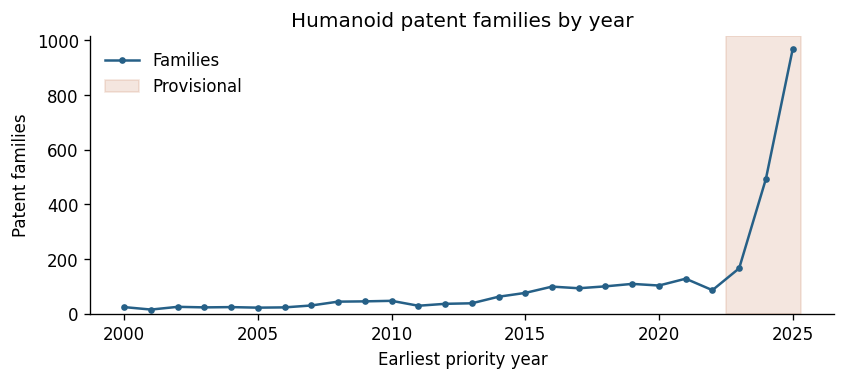

,Humanoids (%),B25J robotics (%),All PATSTAT (%)
Annualized growth,,,
2000–2022,6.0,11.3,4.7
2012–2022,9.1,15.4,5.9
2017–2022,-1.6,5.3,1.9


In [7]:
annual = pd.Series(
    [24, 15, 25, 23, 24, 22, 23, 30, 44, 45, 47, 29, 36,
     38, 62, 76, 99, 93, 100, 109, 103, 128, 86, 166, 493, 967],
    index=range(2000, 2026), name="Families",
)
mature = annual.loc[:COMPLETE_YEAR]
assert annual.sum() == retained and mature.sum() == 1281

ax = annual.plot(figsize=(8, 3), color=BLUE, marker=".", ylabel="Patent families",
                 xlabel="Earliest priority year", title="Humanoid patent families by year")
ax.axvspan(2022.5, 2025.3, color=ORANGE, alpha=0.15, label="Provisional")
ax.set_ylim(bottom=0)
ax.legend(frameon=False, loc="upper left")
plt.show()

# Annualize endpoint growth so periods with different lengths can be compared.
growth = pd.DataFrame(
    {"Start": [2000, 2012, 2017],
     "B25J cumulative change (%)": [943.9, 320.4, 29.7],
     "All PATSTAT cumulative change (%)": [174.2, 78.0, 9.9]},
).set_index("Start")
growth.insert(0, "Humanoid cumulative change (%)", 100 * (mature[COMPLETE_YEAR] / mature[growth.index].to_numpy() - 1))
years = pd.Series(COMPLETE_YEAR - growth.index, index=growth.index)
cagr = ((growth / 100 + 1).pow(1 / years, axis=0) - 1) * 100
cagr.columns = ["Humanoids (%)", "B25J robotics (%)", "All PATSTAT (%)"]
cagr.index = [f"{start}–{COMPLETE_YEAR}" for start in growth.index]
display(cagr.rename_axis("Annualized growth").round(1))

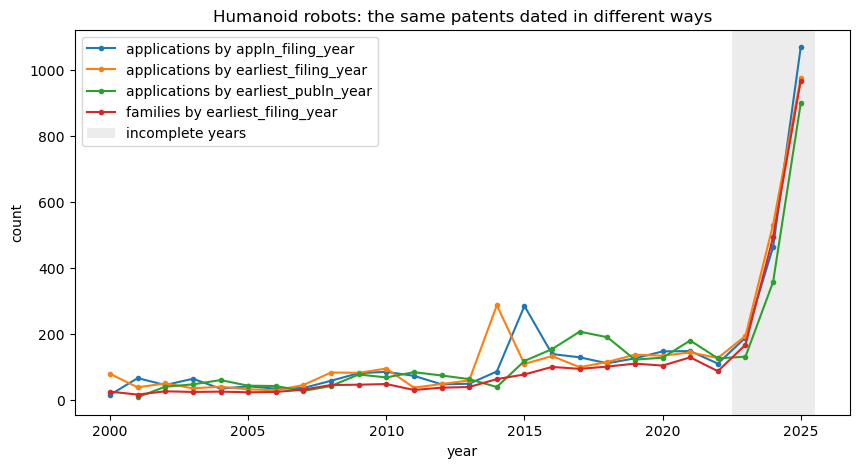

*Application series reproduced from the Step 1 report, p. 20. Compare the application filing-year line with the family priority-year line. They use different units and dating conventions.*

There were **1,281 families through 2022**. From 2012 to 2022 the cohort grew about 9.1% a year, faster than PATSTAT overall and slower than B25J robotics. The 2017–2022 comparison is slightly negative. The conclusion depends on the starting year, and the apparent surge after 2022 is provisional.

### Technology mix

CPC and IPC are technology classifications. Fractional counting divides one family across its distinct subclasses. For example, two subclasses each receive ½. Imma's estimate uses IPC when CPC is missing. WIPO groups the technologies into broader fields.

*Inputs from Step 1, §8. Step 2 below compares subfields across periods.*

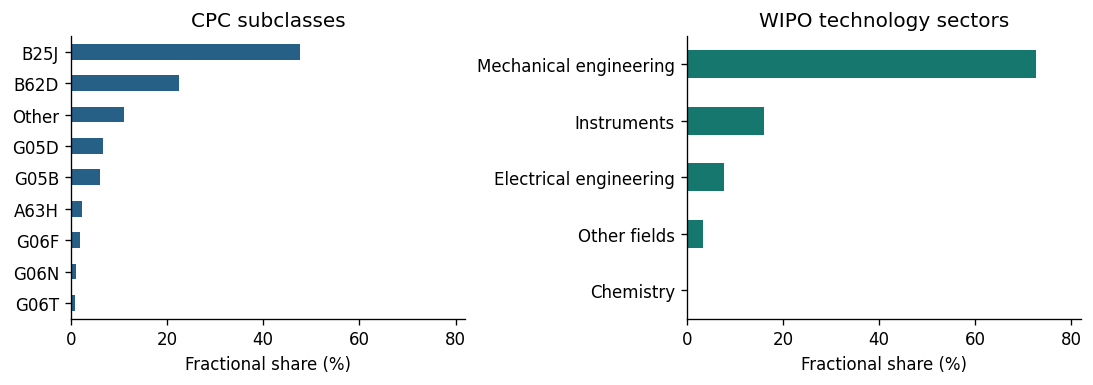

In [8]:
cpc = pd.Series(
    [47.6, 22.4, 6.7, 6.0, 2.4, 1.9, 1.0, 0.8, 11.0],
    index=["B25J", "B62D", "G05D", "G05B", "A63H", "G06F", "G06N", "G06T", "Other"],
)
wipo = pd.Series(
    [72.7, 16.0, 7.7, 3.5, 0.1],
    index=["Mechanical engineering", "Instruments", "Electrical engineering", "Other fields", "Chemistry"],
)
fig, axes = plt.subplots(1, 2, figsize=(9, 3.1), constrained_layout=True)
for values, label, ax, color in zip(
    [cpc, wipo], ["CPC subclasses", "WIPO technology sectors"], axes, [BLUE, TEAL]
):
    values.sort_values().plot.barh(ax=ax, color=color)
    ax.set(title=label, xlabel="Fractional share (%)", xlim=(0, 82))
plt.show()

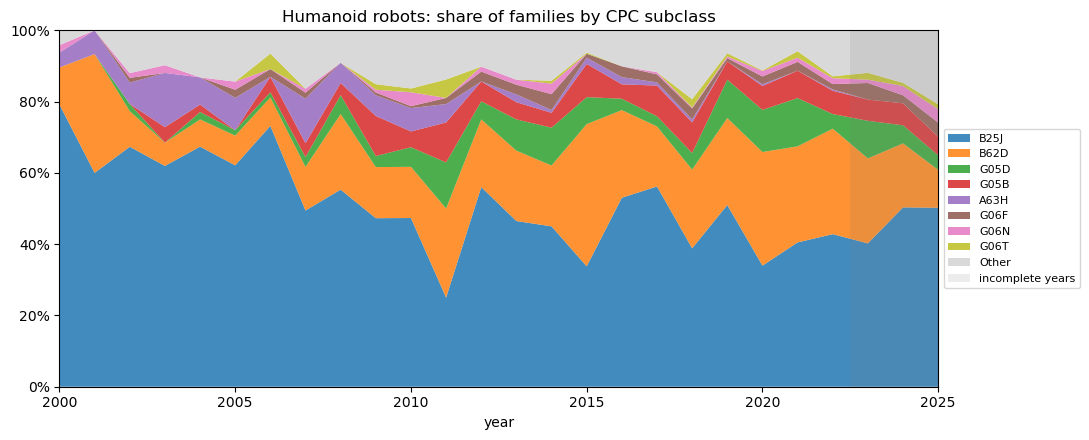

*CPC shares over time from the Step 1 report, p. 28. B25J stays prominent while the share of B62D varies. The WIPO totals above summarize the complete period.*

B25J covers manipulators and robots. B62D also contains a category for legged vehicles, which explains much of its presence in humanoid patents.

### Geography and protection

Filing office indicates where protection was sought. The recorded applicant country indicates where the applicant is based, and the recorded inventor country indicates where inventors are based. Country shares below use known records, fractionally counted within families. The report also shows estimates that use first office for missing countries, which changes the result substantially.

*Inputs from Step 1, §§9–10.*

In [9]:
offices = pd.DataFrame(
    {"Families reaching office": [70, 180, 888, 254, 166],
     "Applications by filing year": [74, 184, 900, 257, 168],
     "Sector families per 10,000 at office": [0.3, 0.2, 0.6, 0.3, 0.5]},
    index=["EP", "US", "CN", "JP", "KR"],
)
display(offices.rename_axis("IP5, 2000–2022"))
# The same family can reach several offices. Applications have one filing office.
print(f"Applications at all offices in 2000–2022: {offices.iloc[:, 1].sum() + 129 + 274:,}.")

countries = pd.DataFrame(
    {"Applicant share (%)": [19.5, 15.0, 33.4, 9.9, 8.9, 2.5, 2.1, 0.5, 8.4],
     "Inventor share (%)": [20.5, 14.9, 32.2, 8.9, 9.7, 2.6, 2.2, 0.6, 8.4]},
    index=["CN", "JP", "KR", "FR", "US", "TW", "DE", "GB", "Other"],
)
display(countries.rename_axis("Known country, 2000–2022"))
print(f"Known country coverage: applicants {365/mature.sum():.1%}, inventors {348/mature.sum():.1%}.")

Applications at all offices in 2000–2022: 1,986.
Known country coverage: applicants 28.5%, inventors 27.2%.


,Families reaching office,Applications by filing year,"Sector families per 10,000 at office"
"IP5, 2000–2022",,,
EP,70,74,0.3
US,180,184,0.2
CN,888,900,0.6
JP,254,257,0.3
KR,166,168,0.5


,Applicant share (%),Inventor share (%)
"Known country, 2000–2022",,
CN,19.5,20.5
JP,15.0,14.9
KR,33.4,32.2
FR,9.9,8.9
US,8.9,9.7
TW,2.5,2.6
DE,2.1,2.2
GB,0.5,0.6
Other,8.4,8.4


China leads as a **filing office**. Only about 28% of families have a recorded applicant or inventor country. Geography of ownership and invention is therefore less certain than office geography.

In 2017–2022, 7.3% of families reached at least two offices and 7.4% used the PCT route. Patents clearly register activity, particularly in mechanical technologies. The data cannot quantify how much know-how firms keep secret. US manufacturing survey evidence also shows firms use secrecy, lead time and patents together. [Cohen, Nelson and Walsh](https://www.nber.org/papers/w7552)

## 2. Compare applicants and subfields

### Concentration

The source standardizes names and merges known aliases before counting. It uses full applicant-family links, so co-applicants each receive one link. Shares below use those links. **CR4/CR8** gives the share of the four/eight biggest applicants. **HHI** adds squared shares, emphasizing large portfolios. **Gini** measures inequality, **CV** measures spread relative to the average, and the **Lotka slope** describes how quickly the number of applicants falls as portfolio size rises.

*Source inputs from Step 2, §§3, 5.1 and 5.2. The concentration series uses overlapping three-year windows.*

,Applicants,CR4 (%),CR8 (%),Effective applicants (1/HHI),Gini,CV,Lotka slope,HHI
All applicants,723,12.581,18.842,132.213,0.498,2.115,-1.435,0.008
Firms only,239,27.903,37.955,35.795,0.528,2.388,-1.115,0.028


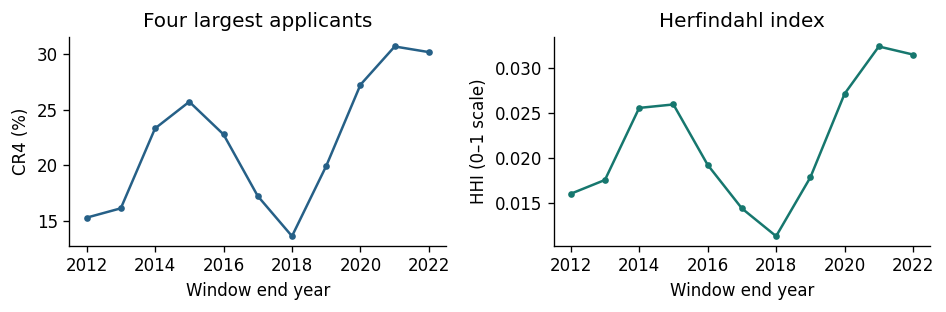

In [10]:
measures = pd.DataFrame(
    {"Applicants": [723, 239], "CR4 (%)": [12.581, 27.903], "CR8 (%)": [18.842, 37.955],
     "Effective applicants (1/HHI)": [132.213, 35.795], "Gini": [0.498, 0.528],
     "CV": [2.115, 2.388], "Lotka slope": [-1.435, -1.115]},
    index=["All applicants", "Firms only"],
)
# Recover HHI from the reported effective number of equal-sized applicants.
measures["HHI"] = 1 / measures["Effective applicants (1/HHI)"]
display(measures.round(3))

windows = pd.DataFrame(
    {"CR4 (%)": [15.287, 16.129, 23.313, 25.714, 22.776, 17.230,
                 13.622, 19.938, 27.246, 30.685, 30.178],
     "Effective applicants": [62.403, 56.948, 39.130, 38.549, 51.982, 69.426,
                              88.340, 56.031, 36.866, 30.889, 31.770]},
    index=range(2012, 2023),
)
windows["HHI"] = 1 / windows["Effective applicants"]
axes = windows[["CR4 (%)", "HHI"]].plot(
    subplots=True, layout=(1, 2), figsize=(8, 2.7), color=[BLUE, TEAL],
    marker=".", legend=False, title=["Four largest applicants", "Herfindahl index"],
)
axes[0, 0].set(ylabel="CR4 (%)", xlabel="Window end year")
axes[0, 1].set(ylabel="HHI (0–1 scale)", xlabel="Window end year")
plt.tight_layout()
plt.show()

The four largest applicants account for **12.6%** of links across the complete years. The three-year CR4 rises from **15.3% to 30.2%** between the windows ending in 2012 and 2022, with HHI also rising. This is evidence of higher concentration over that comparison, with reversals in between.

### Incumbents and entrants

A new entrant first appears in this cohort from 2015 onward. That date describes the observed patent record. A firm can have existed or patented elsewhere for years. In the tables below, 2023–2025 are provisional.

In [11]:
players = pd.DataFrame(
    [("UBTECH", "Firm", "CN", 94, 2016), ("Guangzhou Ligong", "Firm", "CN*", 92, 2024),
     ("Shanghai Fourier", "Firm", "CN", 91, 2023), ("Beijing Institute of Technology", "University", "CN*", 87, 2008),
     ("Zhejiang University", "University", "CN", 67, 2008), ("Shenzhen Zhuji Power", "Firm", "CN*", 59, 2023),
     ("Figure AI", "Firm", "US", 44, 2023), ("Honda", "Firm", "JP", 41, 2000),
     ("Aldebaran", "Firm", "FR", 31, 2008)],
    columns=["Selected applicant", "Type", "Country", "Families", "First observed"],
)
players["Cohort status"] = players["First observed"].ge(2015).map({True: "Entrant", False: "Incumbent"})
display(players.set_index("Selected applicant"))
print("* Country inferred from the first filing office in the source report.")

movement = pd.DataFrame(
    {"Active applicants": [65, 67, 67, 55, 71, 59], "New to sector": [42, 41, 39, 34, 49, 33],
     "Families with an entrant (%)": [62.4, 51.0, 41.3, 38.8, 47.7, 38.4],
     "Observed departures": [39, 41, 39, None, None, None]},
    index=range(2017, 2023),
)
# Missing departures are right-censored. The report requires follow-up to check inactivity.
movement["Disappearance rate (%)"] = 100 * movement["Observed departures"] / movement["Active applicants"]
display(movement.rename_axis("Year").round(1))

* Country inferred from the first filing office in the source report.


,Type,Country,Families,First observed,Cohort status
Selected applicant,,,,,
UBTECH,Firm,CN,94,2016,Entrant
Guangzhou Ligong,Firm,CN*,92,2024,Entrant
Shanghai Fourier,Firm,CN,91,2023,Entrant
Beijing Institute of Technology,University,CN*,87,2008,Incumbent
Zhejiang University,University,CN,67,2008,Incumbent
Shenzhen Zhuji Power,Firm,CN*,59,2023,Entrant
Figure AI,Firm,US,44,2023,Entrant
Honda,Firm,JP,41,2000,Incumbent
Aldebaran,Firm,FR,31,2008,Incumbent


,Active applicants,New to sector,Families with an entrant (%),Observed departures,Disappearance rate (%)
Year,,,,,
2017,65,42,62.4,39.0,60.0
2018,67,41,51.0,41.0,61.2
2019,67,39,41.3,39.0,58.2
2020,55,34,38.8,NaN,NaN
2021,71,49,47.7,NaN,NaN
2022,59,33,38.4,NaN,NaN


One link between firms illustrates how to read a citation: in the study-period tables, Honda's families received 155 sector citations from other applicants and made 67. A citation can be added during examination. It indicates a documented link and provides limited evidence of direct knowledge transfer. *Step 2, §5.2.*

### Fast-growing subfields

Compare equal-length windows and show the starting count alongside the growth rate. Each family may be counted in several subfields.

*Inputs from Step 2, §5.3. The displayed groups are those reported in the source table.*

In [12]:
subfields = pd.DataFrame(
    [(95, 189), (75, 137), (65, 84), (41, 47), (21, 47), (34, 44),
     (22, 34), (14, 28), (17, 28), (12, 28), (25, 27), (9, 22),
     (28, 21), (17, 20), (22, 20), (17, 17), (14, 15)],
    index=["B62D57/03", "B25J9/16", "B25J11/00", "B25J9/00", "G05D1/02", "B25J19/00",
           "B25J17/02", "B25J9/10", "B25J13/08", "B62D57/02", "B25J17/00", "G05D1/08",
           "B25J5/00", "G05B13/04", "B25J19/02", "B25J13/00", "B25J9/12"],
    columns=["2013–2017", "2018–2022"],
)
subfields["Growth (%)"] = 100 * (subfields["2018–2022"] / subfields["2013–2017"] - 1)
subfields["Additional families"] = subfields["2018–2022"] - subfields["2013–2017"]
print("Largest percentage increases")
display(subfields.nlargest(3, "Growth (%)").round(1))
print("Largest increases by family count")
display(subfields.nlargest(3, "Additional families").round(1))

Largest percentage increases
Largest increases by family count


,2013–2017,2018–2022,Growth (%),Additional families
G05D1/08,9,22,144.4,13
B62D57/02,12,28,133.3,16
G05D1/02,21,47,123.8,26


,2013–2017,2018–2022,Growth (%),Additional families
B62D57/03,95,189,98.9,94
B25J9/16,75,137,82.7,62
G05D1/02,21,47,123.8,26


G05D1/08 leads by percentage in the reported table, rising from 9 to 22 families. B62D57/03 adds the most families, rising from 95 to 189. Comparing the two measures keeps small starting counts in perspective.

### PEST implications for Electrolux

| Force | Evidence and implication |
| --- | --- |
| Political | The EU Machinery Regulation generally applies from January 2027. Safety and conformity assessment matter for a product entering the EU market. [EUR-Lex](https://eur-lex.europa.eu/eli/reg/2023/1230/2026-07-27/eng) |
| Economic | IFR counted about 542,000 industrial robot installations in 2024. That provides evidence of a factory robotics market. Household humanoid demand remains unmeasured by that figure. [IFR World Robotics](https://ifr.org/img/worldrobotics/Executive_Summary_WR_2025_Industrial_Robots.pdf) |
| Social | An ageing EU population makes assistance at home a plausible use case. Demographics alone give little evidence of willingness to adopt a humanoid. [Eurostat](https://ec.europa.eu/eurostat/statistics-explained/index.php?stable=1&title=Population_structure_and_ageing) |
| Technological | DeepMind has demonstrated whole-body control on a humanoid platform. A partnership could reduce the need to develop the control stack in-house. Reliability in household tasks still needs field evidence. [Google DeepMind](https://deepmind.google/blog/gemini-robotics-2-brings-whole-body-intelligence-to-robots/) |

## 3. Score mature patent portfolios

The source screened firms for at least 10 mature families through 2021 and at least three usable indicators for scoring. There are seven scored firms from eight candidates. These four proxies describe different aspects of patent portfolios.

| Indicator | Meaning |
| --- | --- |
| Volume | Share of the sector's cohort families. It uses the full 2000–2025 count, including provisional years. |
| Influence | Forward citations during the first five years relative to the PATSTAT mean for the same CPC subclass and priority year. The five-year window limits this to priority years through 2017. |
| Success | Average across families of the fraction of eligible applications granted, using filings through 2020. |
| Globalization | Mean number of filing jurisdictions per family, using priority years through 2021. |

For influence, publication-level origin distinguishes applicant from examiner citations where recorded. In the source's geographic subset, 54% of 144 applicant citations stayed in the same inventor country, versus 32% under its reference model. This is a limited subset. For international reach, the main score uses offices, with quadrilateral share and EP validations as checks.

### Combine and test

Convert each indicator to rank points, with 100 for first. Weighted reciprocal rank fusion gives influence 35%, globalization 25%, success 20% and volume 20%. The sensitivity checks give the indicators equal weight and switch from rank points to ratios to the mean.

*Inputs from Step 3, pp. 63, 70, 75, 87 and 94. The reciprocal rank fusion method follows the course tutorial and the team's weights.*

,Volume (%),Influence,Success (%),Globalization,Indicators,Present_score
UBTECH,3.23,NaN,87.21,1.47,3,87.18
Honda,1.41,1.07,79.70,2.37,4,86.67
Samsung,0.83,1.38,72.35,2.64,4,86.56
Aldebaran,1.07,0.94,63.39,9.18,4,82.33
Toyota,0.86,0.53,64.00,1.16,4,67.81
Tmsuk,0.45,0.54,10.26,1.54,4,67.37
Kawada Kogyo,0.45,0.14,61.54,1.00,4,60.44


,Weighted RRF rank,Equal-weight RRF rank,Ratio to mean rank
UBTECH,1,1,2
Honda,2,2,4
Samsung,3,3,3
Aldebaran,4,4,1
Toyota,5,5,5
Tmsuk,6,6,6
Kawada Kogyo,7,7,7


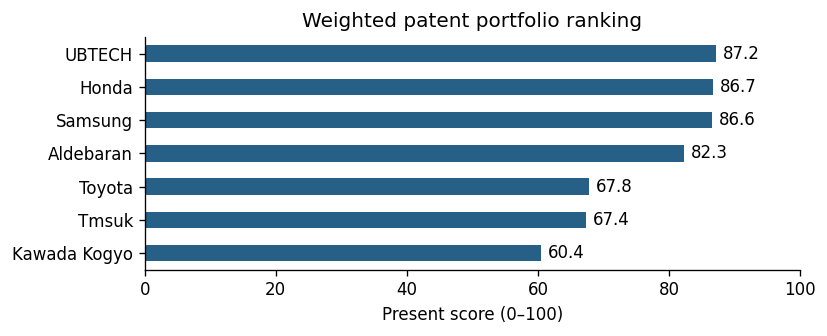

In [13]:
firms = pd.DataFrame(
    [(94, None, 87.21, 1.47), (41, 1.07, 79.70, 2.37),
     (24, 1.38, 72.35, 2.64), (31, 0.94, 63.39, 9.18),
     (25, 0.53, 64.00, 1.16), (13, 0.54, 10.26, 1.54),
     (13, 0.14, 61.54, 1.00), (14, None, None, 1.00)],
    index=["UBTECH", "Honda", "Samsung", "Aldebaran", "Toyota", "Tmsuk", "Kawada Kogyo", "Leju"],
    columns=["Family count", "Influence", "Success (%)", "Globalization"],
)
# Recompute volume from counts to avoid creating ties from rounded percentages.
firms["Volume (%)"] = 100 * firms["Family count"] / annual.sum()
weights = pd.Series({"Volume (%)": .20, "Influence": .35, "Success (%)": .20, "Globalization": .25})
indicators = firms[weights.index]
eligible = indicators.notna().sum(axis=1).ge(3)
scored = indicators.loc[eligible]
assert len(scored) == 7 and not eligible.loc["Leju"]

# Divide each weighted sum by the weights of the available indicators.
# UBTECH's nine mature citation families leave its influence unscored.
def combine(points, weights):
    available_weight = points.notna().mul(weights).sum(axis=1)
    return points.mul(weights).sum(axis=1) / available_weight

positions = scored.rank(ascending=False, method="min")
constant = len(scored)
rank_points = 100 * (constant + 1) / (constant + positions)
score = combine(rank_points, weights)
assert abs(score.loc["UBTECH"] - 87.18) < 0.01

# Keep the same firms and inputs while changing one scoring assumption at a time.
equal = combine(rank_points, pd.Series(1.0, index=weights.index))
relative = combine(100 * scored / scored.mean(), weights)
rankings = pd.DataFrame({"Weighted RRF": score, "Equal-weight RRF": equal, "Ratio to mean": relative})
ranking_table = rankings.rank(ascending=False, method="min").astype(int).add_suffix(" rank")
result = scored.assign(Indicators=scored.notna().sum(axis=1), Present_score=score)
display(result.sort_values("Present_score", ascending=False).round(2))
display(ranking_table.loc[result["Present_score"].sort_values(ascending=False).index])

ax = score.sort_values().plot.barh(figsize=(7, 2.9), color=BLUE, xlim=(0, 100),
                                   xlabel="Present score (0–100)", title="Weighted patent portfolio ranking")
ax.bar_label(ax.containers[0], fmt="%.1f", padding=4)
plt.tight_layout()
plt.show()

In [14]:
# Check an alternative internationalization indicator on the same set of firms.
quadrilateral_share = pd.Series(
    [0, 14.63, 13.64, 85.71, 0, 7.69, 0],
    index=["UBTECH", "Honda", "Samsung", "Aldebaran", "Toyota", "Tmsuk", "Kawada Kogyo"],
)
alternative = scored.assign(Globalization=quadrilateral_share)
positions_alt = alternative.rank(ascending=False, method="min")
score_alt = combine(100 * (constant + 1) / (constant + positions_alt), weights)
display(pd.DataFrame({"By offices": score, "By quadrilateral share": score_alt}).round(2))

,By offices,By quadrilateral share
UBTECH,87.18,87.18
Honda,86.67,88.89
Samsung,86.56,84.33
Aldebaran,82.33,82.33
Toyota,67.81,69.09
Tmsuk,67.37,67.37
Kawada Kogyo,60.44,62.82


UBTECH, Honda and Samsung are separated by less than one point in the main ranking. The ratio-to-mean method puts Aldebaran first, helped by its 9.18 jurisdictions per family. Aldebaran also averaged 12.47 validated states among its 19 granted EP families with the source's validation measure. Leju has too few measured indicators to receive a score. The scores are patent indicators for this cohort and do not estimate the companies' financial values.

## What to say in the presentation

1. **Define the inventions.** “I use our title-screened PATSTAT cohort and count each family once. The team found 37 relevant inventions in a fresh sample of 40.”
2. **Describe the field.** “There are 1,281 families through 2022. The long-run trend rises, but 2017–2022 is broadly flat. Mechanical engineering dominates, and China is the leading filing office.”
3. **Compare the applicants.** “The field is fragmented over the full period, but the top four took about 30% of applicant-family links in the latest complete three-year window. Several prominent entrants first show up after 2022.”
4. **Explain the score.** “I compare patent volume, citations, grants and international filing. The top three are close, and the winner changes with the scoring method. Aldebaran stands out for international filing.”

If asked where the numbers came from, distinguish the team's PATSTAT retrieval and manual review from the calculations this notebook reruns.

**Source notes.** Group 34's Imma reports supply the PATSTAT aggregates and the two credited Step 1 figures. The group ZIP is a reference for the alternate segmentation. The linked repository maps Project Work Steps 0–3 and supplies the analytical methods. The separate future-score planning PDF concerns a later step.